# Stage 2: genuine pilot evidence and cost decision

Stage 2 is complete: all 19 native task IDs have valid diagnostic artifacts, and two 21-day Kaggle validation episodes completed with matched baselines. Full evaluations have not started. Run All reads committed sanitized evidence, creates no API client and does not read credentials.

Pilot results are distinct from full coverage. Native metrics are task-specific; Factset is an extension. The Kaggle data and economic responses are synthetic. Returned model identifiers are not independently attested model identities.

In [1]:
import hashlib
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
artifacts = ROOT / 'docs/results/stage2'
read = lambda name: json.loads((artifacts / name).read_text(encoding='utf-8'))
report = read('pilot_cost_report.json')
budget = read('budget_summary.json')
validations = read('native_pilot_validations.json')
kaggle_checks = read('kaggle_pilot_validations.json')
reviews = read('kaggle_quality_reviews.json')
model_summary = read('model_usage_summary.json')
assert sum(m['attempts'] for m in model_summary) == report['totals']['attempts'] == budget['attempts'] == 237
assert len({r['task'] for r in validations if r['status'] == 'validated_complete'}) == 19
assert sum(m['missing_usage_attempts'] for m in model_summary) == budget['uncertain_attempts'] == 3
assert abs(sum(m['known_estimated_cost_usd'] for m in model_summary) - budget['known_cost_usd']) < 1e-9
assert budget['pending_attempts'] == budget['blocking_uncertain_attempts'] == 0
assert budget['bounded_carried_attempts'] == 3 and budget['exposure_usd'] < budget['cap_usd'] == 2
for name, digest in read('artifact_manifest.json')['files'].items():
    assert hashlib.sha256((artifacts / name).read_bytes().replace(b'\r\n', b'\n')).hexdigest() == digest, name
print('Aggregate artifact hashes, counts, native coverage and project cost estimates reconcile.')

Aggregate artifact hashes, counts, native coverage and project cost estimates reconcile.


## Native pilots and retained failures

Eleven reasoning cases yielded eight correct and three incorrect answers. One case per dataset is not a dataset-level accuracy estimate. The original CodeFinQA response was valid but had the wrong sign; its score was retained.

Consulting completed one interview and judge (8/10 overall). BeerGame completed 25 weeks, with controlled-role cost 22,950; some native aggregate fields are null despite episode metrics. EDT completed 96 steps with negative accumulated earnings (-3,478,500). All four Retail days advanced explicitly. ICBE completed 24 choices after the documented 150-to-4,096 output-limit compatibility amendment; genuine late-phase behavior is unmeasured.

The original Consulting 503, ICBE truncation/canceled peer, and seven-day Kaggle timeout cohort remain failed/incomplete. Their cost is included. New complete cohorts do not overwrite those records.

In [2]:
usage = pd.DataFrame(report['observations'])
usage['correct'] = usage['native_score'].map(lambda s: s.get('correct') if isinstance(s, dict) else None)
usage[['task', 'cohort', 'validation_status', 'attempts', 'correct', 'input_tokens', 'output_tokens', 'missing_usage_attempts', 'known_estimated_cost_usd']]

,task,cohort,validation_status,attempts,correct,input_tokens,output_tokens,missing_usage_attempts,known_estimated_cost_usd
0,firm:beergame,pilot_01,validated_complete,25,NaN,5103,925,0,0.005641
1,firm:CodeFinQA,pilot_02,validated_complete,1,0.0,925,144,0,0.000962
2,firm:CodeTAT-QA,pilot_03,validated_complete,1,1.0,825,163,0,0.000946
3,firm:consulting,pilot_04,requires_review,11,NaN,22692,1643,1,0.009682
4,firm:consulting,pilot_05,validated_complete,13,NaN,32024,2083,0,0.012796
5,firm:ConvFinQA,pilot_06,validated_complete,1,1.0,867,86,0,0.000776
6,firm:edt,pilot_07,validated_complete,1,NaN,1709,107,0,0.001369
7,firm:factset,pilot_08,validated_complete,1,0.0,431,226,0,0.000855
8,firm:FinCode,pilot_09,validated_complete,1,1.0,380,94,0,0.000484
9,firm:finer,pilot_10,validated_complete,1,1.0,1792,279,0,0.001863


## Matched Kaggle validation outcomes

All six complete episodes use the same selected series and validation window. Matched initial observations, prepared inputs and base-demand hashes were checked. Only current state and strictly past histories are sent to the policy.

Contribution below is in synthetic dataset monetary units, not API dollars. LLM-with-fallback contribution was below adaptive in both validation scenarios. One inspected validation series does not establish population performance or a real-world causal shock effect. Daily rows are repeated measurements, not independent replications.

In [3]:
summary = pd.read_csv(artifacts / 'kaggle_validation_summary.csv')
daily = pd.read_csv(artifacts / 'kaggle_validation_daily.csv')
assert len(summary) == 6 and len(daily) == 126
assert len(kaggle_checks) == 2 and all(v['status'] == 'validated_complete' for v in kaggle_checks)
matched = read('matched_validation_inputs.json')
assert matched['identical_initial_observations'] and matched['identical_prepared_inputs'] and matched['identical_base_demand_paths']
paths = set()
for _, group in daily.groupby(['scenario', 'policy']):
    paths.add(hashlib.sha256(group[['date', 'sku_id', 'base_demand']].to_csv(index=False).encode()).hexdigest())
assert len(paths) == 1
summary.pivot(index='scenario', columns='policy', values=['contribution', 'fill_rate'])

contribution                                 fill_rate  \
policy                  adaptive         fixed llm_with_fallback  adaptive   
scenario                                                                     
control              40167.98625  38527.033125      35313.166875  0.998621   
delivery_disruption  39436.45125  37715.829375      35854.402500  0.975610   

                                                 
policy                  fixed llm_with_fallback  
scenario                                         
control              0.980718          0.971304  
delivery_disruption  0.958777          0.981784

## Repairs, fallbacks and the review trigger

42 first attempts plus 15 repairs produced 57 responses in the complete LLM episodes. Eighteen responses violated cash affordability. First-pass validity was 27/42 (64.3%); after repair, 39/42 decisions came from the model and 3/42 (7.1%) used the explicitly labeled adaptive fallback.

The 5% threshold triggered review. Recomputed overruns were material (at least 1.98 synthetic units), every applied action was feasible, and each fallback exactly matched the frozen adaptive policy. The recorded review retains this operational policy and its negative findings. All fallback days stay in primary operational outcomes; fallback-free subsets would be selected. Full evaluation still requires budget approval.

In [4]:
llm = summary[summary['policy'] == 'llm_with_fallback'].copy()
llm['first_pass_valid_days'] = llm['decision_opportunities'] - llm['repair_days']
llm['valid_after_repair_days'] = llm['repair_days'] - llm['fallback_days']
assert llm['decision_opportunities'].sum() == 42
assert llm['repair_days'].sum() == 15 and llm['fallback_days'].sum() == 3
assert all(r['status'] == 'reviewed' and r['decision'] == 'retain_frozen_operational_policy' for r in reviews)
llm[['scenario', 'first_pass_valid_days', 'valid_after_repair_days', 'fallback_days', 'invalid_responses']]

,scenario,first_pass_valid_days,valid_after_repair_days,fallback_days,invalid_responses
0,control,14,6,1,8
1,delivery_disruption,13,6,2,10


## Aggregate usage and conservative project cost

The project accounting holds three unknown charges at their full original reservations. It does not invent usage, release those reserves or reset earlier spending. Costs below are token-derived research estimates at public uncached tariffs; they are not provider invoices or the cash purchase price of credit. Limits depend on tariff and gateway token ceilings, not a provider-enforced quota.

Request-level telemetry, exact request/cohort identifiers, approval history and provider account/billing records remain in ignored local storage. This public notebook uses deidentified aggregate model usage and synthetic experiment metrics only.

In [5]:
display(pd.DataFrame(model_summary))
pd.DataFrame([budget]).T

,requested_model,returned_models,attempts,missing_usage_attempts,input_tokens,output_tokens,known_estimated_cost_usd,median_latency_seconds,p95_latency_seconds
0,deepseek-v3.2,[deepseek-v3.2],8,0,2316,2883,0.015937,5.205745,6.411883
1,gpt-4.1-mini-2025-04-14,[gpt-4.1-mini-2025-04-14],207,2,1212836,18002,0.823328,2.590536,14.430388
2,gpt-4o-mini-2024-07-18,[gpt-4o-mini-2024-07-18],22,1,45564,3329,0.010598,3.540296,14.085039


,0
currency,USD_gateway_credit
attempts,237
known_cost_usd,0.849864
unresolved_reserved_usd,0.01901
exposure_usd,0.868873
pending_attempts,0
uncertain_attempts,3
bounded_carried_attempts,3
bounded_carried_reserve_usd,0.01901
blocking_uncertain_attempts,0


## Full-scope projection and budget decision

Each successful pilot is scaled by its frozen case or horizon count. ICBE uses the corrected output-budget cohort and observed paired concurrency. Native one-time initialization is counted once before scaling per-unit time; full Kaggle episodes each require initialization.

Low/base/high use declared 0.75x / 1x / 2x planning assumptions, not confidence intervals or guaranteed bounds. The base is about $136.58 and 33 experiment hours; Retail contributes about $134.63 and 30 hours. One-day pilots do not measure later context, agent survival or restart overhead.

The proposed first-draft route is $6 total for non-Retail native tasks and the Kaggle primary matrix. Full Retail remains on the longer route. The full-scope proposal is $350 total. Both include pilot exposure, at least 20% reserve and explicit attempt ceilings. Neither is approved; no full evaluation has begun.

In [6]:
projection = pd.DataFrame(report['projections'])
assert projection['cost_base_scenario_usd'].notna().all()
assert abs(projection['cost_base_scenario_usd'].sum() - report['totals']['full_suite_cost_estimate_usd']) < 1e-8
projection[['task', 'full_units', 'full_horizon', 'projected_calls_base', 'cost_low_scenario_usd', 'cost_base_scenario_usd', 'cost_high_scenario_usd', 'projected_elapsed_seconds_base']]

,task,full_units,full_horizon,projected_calls_base,cost_low_scenario_usd,cost_base_scenario_usd,cost_high_scenario_usd,projected_elapsed_seconds_base
0,retail:dynamic_middle,1.0,180.0,3420.0,21.831419,29.108559,58.217118,19827.440076
1,retail:dynamic_hard,1.0,180.0,3600.0,22.684302,30.245736,60.491472,28012.630315
2,retail:still_middle,1.0,180.0,4320.0,23.741862,31.655817,63.311633,27878.615594
3,retail:still_hard,1.0,180.0,3960.0,32.717673,43.623564,87.247128,32977.173439
4,firm:FinCode,7.0,NaN,7.0,0.002543,0.003391,0.006782,97.478637
5,firm:CodeFinQA,50.0,NaN,50.0,0.036069,0.048092,0.096184,164.786283
6,firm:CodeTAT-QA,50.0,NaN,50.0,0.035492,0.047323,0.094646,669.234149
7,firm:SEC-NUM,50.0,NaN,50.0,0.034627,0.046170,0.092339,74.368206
8,firm:TAT-QA,50.0,NaN,50.0,0.029653,0.039537,0.079075,746.831570
9,firm:ConvFinQA,50.0,NaN,50.0,0.029100,0.038800,0.077601,133.074097


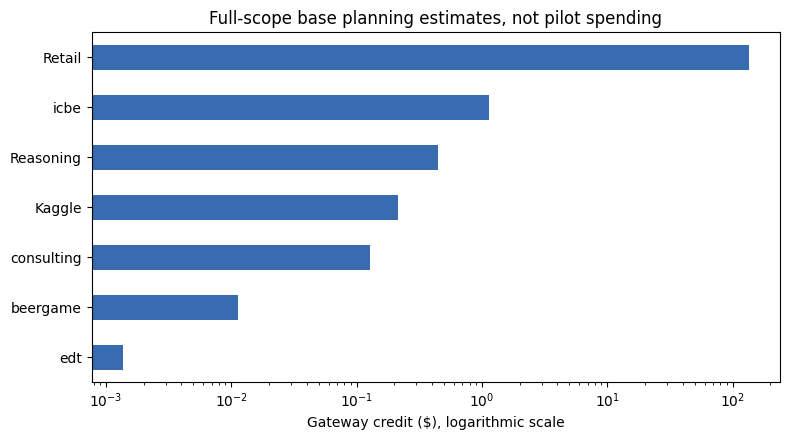

Base full-scope credit: 136.58
Base elapsed hours: 33.0


,approved,currency,proposed_total_cap_inclusive_of_pilots,carry_forward_existing_pilot_exposure_usd,proposed_max_client_attempts_inclusive_of_pilots,unallocated_reserve_fraction_at_least,retail_full_horizons_included,evaluation_requires_separate_approval,qualification
0,False,USD_gateway_credit,6,0.868873,3000,0.2,False,True,Proposal from declared high planning scenarios...
1,False,USD_gateway_credit,350,0.868873,30000,0.2,True,True,Proposal from declared high planning scenarios...


In [7]:
family = projection.copy()
family['family'] = family['task'].map(lambda t: 'Retail' if t.startswith('retail:') else 'Kaggle' if t.startswith('kaggle:') else 'Reasoning' if t.startswith('firm:') and t.split(':')[1] not in ['consulting', 'beergame', 'edt'] else t.split(':')[-1])
plot_data = family.groupby('family')['cost_base_scenario_usd'].sum().sort_values()
ax = plot_data.plot.barh(figsize=(8, 4.5), color='#386cb0', logx=True)
ax.set(xlabel='Gateway credit ($), logarithmic scale', ylabel='', title='Full-scope base planning estimates, not pilot spending')
plt.tight_layout()
figures = ROOT / 'docs/assets/stage2'
figures.mkdir(parents=True, exist_ok=True)
plt.savefig(figures / 'full_scope_cost_base.png', dpi=160, bbox_inches='tight')
plt.show()
print('Base full-scope credit:', round(report['totals']['full_suite_cost_estimate_usd'], 2))
print('Base elapsed hours:', round(report['totals']['full_suite_projected_elapsed_hours_base'], 1))
display(pd.DataFrame([read('budget_proposal_nonretail_first_draft.json'), read('budget_proposal_full_scope.json')]))

## Reproduce

From the project root, run `python scripts/summarize_pilot_costs.py` and `python scripts/export_stage2_evidence.py` to regenerate local saved-output summaries. The notebook reads the committed portable subset, including failed cohorts, validation reviews and normalized-text artifact hashes.

Next-stage entry requires an explicit budget/scope approval carrying forward the pilot ledger's $0.868873311 exposure. The existing $2 approval remains pilot-only. The primary-window prior-use uncertainty recorded in Stage 1 remains applicable.